# Part 2: Question 1, Predicting Battery-Electric vs Plug-in Hybrid

**Personal project: Electric Vehicle Adoption in Washington State**

**Name:** Bernard Issifu

**Question 1.** Can location and time predict whether a registered EV is fully battery-electric (BEV)
rather than a plug-in hybrid (PHEV)?

Uses the cleaned data from Part 1 (run `01_data_preparation_eda.ipynb` first). The R version is
`r/02_q1_classification.Rmd`.

In [1]:
# ---- Setup ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             balanced_accuracy_score, roc_curve, confusion_matrix)

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"

df = pd.read_csv("../data/processed/ev_clean_python.csv", dtype={"zip": str, "leg_district": str})
df["log_city_evs"] = np.log10(df["city_evs"])
print(df.shape)
print(f"BEV share: {df['bev'].mean():.2%}")

(299303, 16)
BEV share: 80.58%


---
# 1. Approach

**Features (location and time only).** Model year; log10 of the number of EVs registered in the
vehicle's city (an urbanity proxy); region (Seattle metro, other western WA, eastern WA); county (15
largest, others grouped); primary electric utility (6 largest, others grouped); and legislative district
(49 districts). Numeric features are standardized and categorical ones one-hot encoded with a reference
level.

**Excluded on purpose.** Make, model, electric range and incentive eligibility essentially *define* the
vehicle type; a quick check below shows make and model alone give an AUC of 0.9997. The question is
whether *where and when* a car is registered tells us its type.

**Imbalance and metrics.** 80.6% of vehicles are BEVs, so classes are weighted inversely to their
frequency, and models are compared by **ROC-AUC**, **balanced accuracy**, BEV **recall, precision and
F1**, and the **recall of PHEVs** (the minority class).

**Models.** Logistic regression; a decision tree (depth 6, at least 200 vehicles per leaf); a random
forest (200 trees, at least 50 vehicles per leaf). Data are split 80/20, stratified on the outcome. With
about 240,000 training vehicles, the random forest is trained on a random 80,000-vehicle subsample, and
5-fold cross-validation uses a 50,000-vehicle subsample, to keep run time reasonable.

In [2]:
num_cols = ["model_year", "log_city_evs"]
cat_cols = ["region", "county_grp", "utility", "leg_district"]
X, y = df[num_cols + cat_cols], df["bev"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Training: {len(X_train):,}  Test: {len(X_test):,}")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

# Sanity check: make and model alone nearly determine the type
check = Pipeline([("prep", OneHotEncoder(handle_unknown="ignore")),
                  ("model", LogisticRegression(max_iter=3000))])
mm = df[["Make", "Model"]]
check.fit(mm.loc[X_train.index], y_train)
print(f"Sanity check, make + model only: test AUC = "
      f"{roc_auc_score(y_test, check.predict_proba(mm.loc[X_test.index])[:, 1]):.4f}")

Training: 239,442  Test: 59,861


Sanity check, make + model only: test AUC = 0.9997


---
# 2. Training and evaluation

In [3]:
models = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=3000),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=200,
                                            class_weight="balanced", random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                                            class_weight="balanced_subsample", n_jobs=2,
                                            random_state=42),
}
rf_idx = X_train.sample(80_000, random_state=42).index      # random forest training subsample
cv_idx = X_train.sample(50_000, random_state=1).index       # cross-validation subsample
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fitted, probs, rows = {}, {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train.loc[cv_idx], y_train.loc[cv_idx], cv=cv,
                             scoring="roc_auc", n_jobs=2)
    tr = rf_idx if name == "Random forest" else X_train.index
    pipe.fit(X_train.loc[tr], y_train.loc[tr])
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    fitted[name], probs[name] = pipe, p
    rows.append({"model": name,
                 "CV ROC-AUC (mean ± sd)": f"{cv_auc.mean():.3f} ± {cv_auc.std():.3f}",
                 "Test ROC-AUC": roc_auc_score(y_test, p),
                 "Balanced accuracy": balanced_accuracy_score(y_test, pred),
                 "BEV recall": recall_score(y_test, pred),
                 "BEV precision": precision_score(y_test, pred),
                 "BEV F1": f1_score(y_test, pred),
                 "PHEV recall": recall_score(1 - y_test, 1 - pred)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV ROC-AUC (mean ± sd),Test ROC-AUC,Balanced accuracy,BEV recall,BEV precision,BEV F1,PHEV recall
model,,,,,,,
Logistic regression,0.616 ± 0.008,0.620,0.582,0.615,0.850,0.714,0.548
Decision tree,0.646 ± 0.008,0.649,0.604,0.641,0.860,0.735,0.568
Random forest,0.644 ± 0.010,0.651,0.608,0.656,0.861,0.745,0.560


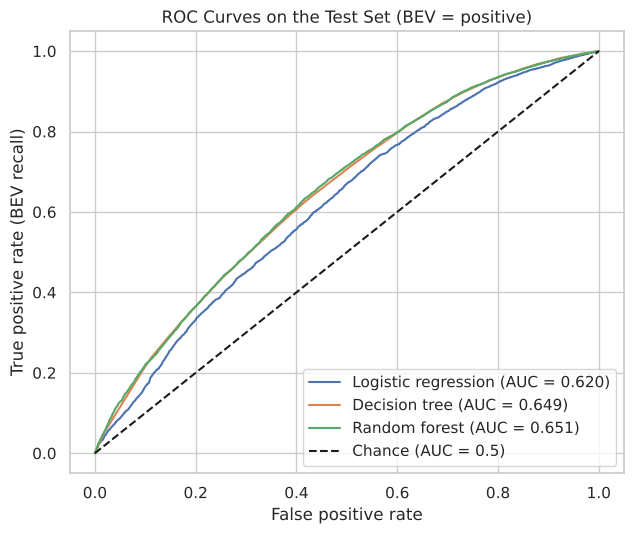

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
ax.set_title("ROC Curves on the Test Set (BEV = positive)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (BEV recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_roc_curves.png", dpi=150)
plt.show()

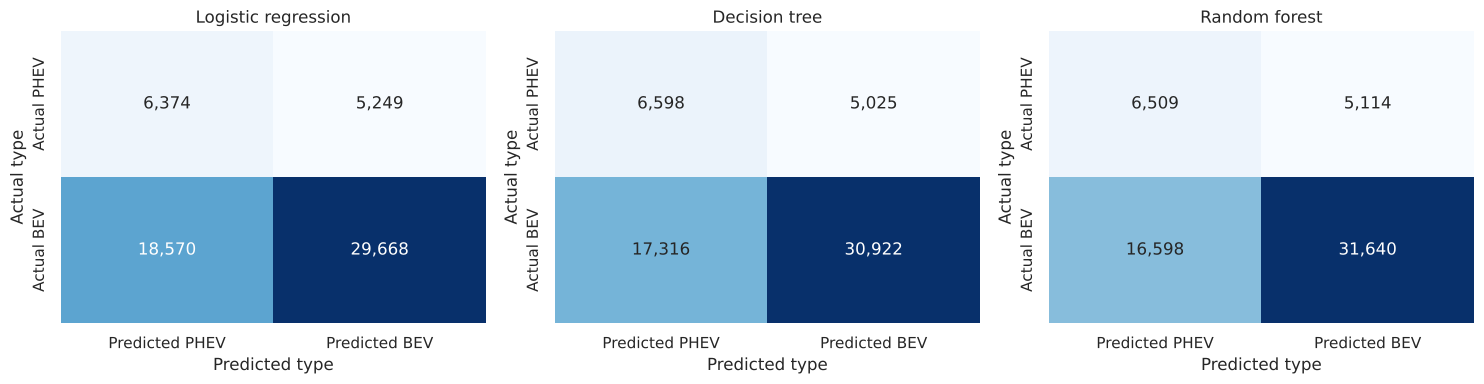

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted PHEV", "Predicted BEV"],
                yticklabels=["Actual PHEV", "Actual BEV"])
    ax.set_title(name)
    ax.set_xlabel("Predicted type")
    ax.set_ylabel("Actual type")
plt.tight_layout()
plt.show()

**Interpretation.** Location and time predict vehicle type only modestly. Test ROC-AUC is 0.620 for
logistic regression and about 0.65 for the decision tree (0.649) and random forest (0.651), with
matching cross-validated scores, so the comparison is stable. The tree-based models do better because
the BEV share changes non-linearly with model year (it dips for 2024–2025), which a single linear term
cannot follow. At the 0.5 threshold, the random forest finds 65.6% of BEVs with 86.1% precision and 56.0%
of PHEVs; balanced accuracy is about 0.61, against 0.5 for guessing.

---
# 3. Which factors matter?

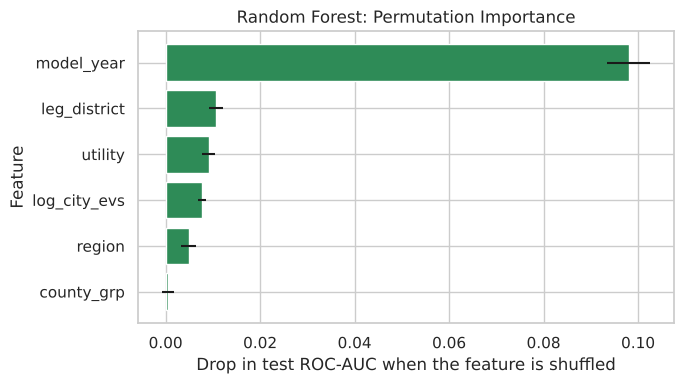

,mean_auc_drop,sd
model_year,0.0980,0.0045
leg_district,0.0107,0.0015
utility,0.0091,0.0014
log_city_evs,0.0077,0.0008
region,0.0049,0.0016
county_grp,0.0005,0.0012


In [6]:
# Permutation importance of the random forest on a 20,000-vehicle test subsample
te_idx = X_test.sample(20_000, random_state=42).index
perm = permutation_importance(fitted["Random forest"], X_test.loc[te_idx], y_test.loc[te_idx],
                              scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=2)
imp = pd.DataFrame({"mean_auc_drop": perm.importances_mean, "sd": perm.importances_std},
                   index=X_test.columns).sort_values("mean_auc_drop", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index[::-1], imp["mean_auc_drop"][::-1], xerr=imp["sd"][::-1], color="seagreen")
ax.set_title("Random Forest: Permutation Importance")
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_permutation_importance.png", dpi=150)
plt.show()
imp.round(4)

In [7]:
# Logistic regression odds ratios (per standard deviation for numeric features)
lr = fitted["Logistic regression"]
names = [n.replace("num__", "").replace("cat__", "")
         for n in lr.named_steps["prep"].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps["model"].coef_[0]), index=names)
print("Numeric features:")
print(odds[num_cols].round(3))
print("\nRegion and utility terms:")
print(odds[[n for n in names if n.startswith(("region_", "utility_"))]].round(3))

Numeric features:
model_year      1.388
log_city_evs    1.028
dtype: float64

Region and utility terms:
region_Other western WA                  1.211
region_Seattle metro                     1.290
utility_CITY OF SEATTLE - (WA)           1.359
utility_MODERN ELECTRIC WATER COMPANY    0.947
utility_Other                            0.962
utility_PACIFICORP                       0.595
utility_PUD NO 1 OF CHELAN COUNTY        1.000
utility_PUGET SOUND ENERGY INC           1.131
dtype: float64


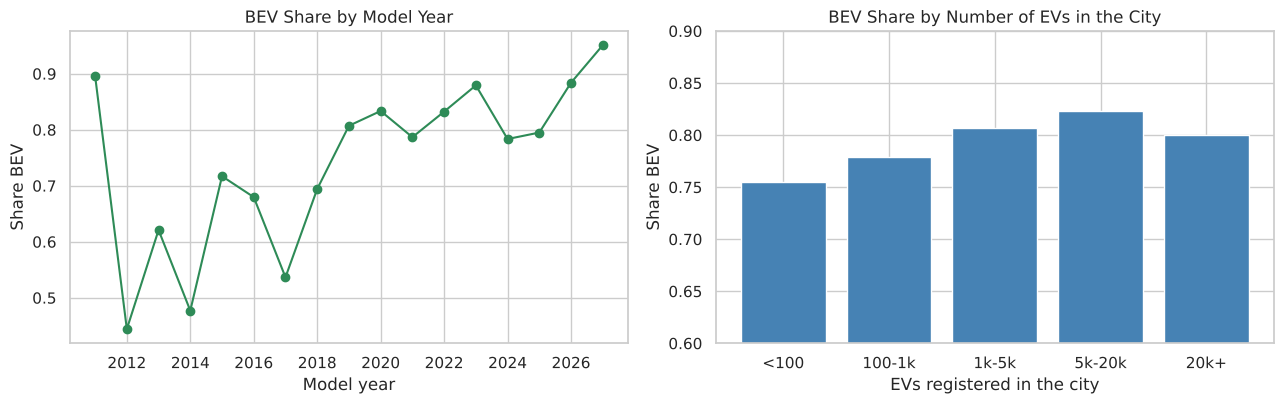

,vehicles,bev_share
city_evs,,
<100,6963,0.755
100-1k,42716,0.779
1k-5k,105123,0.807
5k-20k,99067,0.823
20k+,45434,0.800


In [8]:
# How the BEV share changes with model year and urbanity (the two top features)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
df.groupby("model_year")["bev"].mean().plot(ax=axes[0], marker="o", color="seagreen")
axes[0].set_title("BEV Share by Model Year")
axes[0].set_xlabel("Model year")
axes[0].set_ylabel("Share BEV")
bins = pd.cut(df["city_evs"], [0, 100, 1000, 5000, 20000, 100000],
              labels=["<100", "100-1k", "1k-5k", "5k-20k", "20k+"])
share = df.groupby(bins, observed=True)["bev"].mean()
axes[1].bar(share.index.astype(str), share.values, color="steelblue")
axes[1].set_title("BEV Share by Number of EVs in the City")
axes[1].set_xlabel("EVs registered in the city")
axes[1].set_ylabel("Share BEV")
axes[1].set_ylim(0.6, 0.9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_top_features.png", dpi=150)
plt.show()
df.groupby(bins, observed=True)["bev"].agg(vehicles="size", bev_share="mean").round(3)

Decision tree top splits (thresholds are standardized: model year -1.26 is about 2018).

In [9]:
tree = fitted["Decision tree"]
tnames = [n.replace("num__", "").replace("cat__", "")
          for n in tree.named_steps["prep"].get_feature_names_out()]
print(export_text(tree.named_steps["model"], feature_names=tnames, max_depth=2))

|--- model_year <= -1.26
|   |--- model_year <= -1.58
|   |   |--- model_year <= -3.53
|   |   |   |--- truncated branch of depth 2
|   |   |--- model_year >  -3.53
|   |   |   |--- truncated branch of depth 4
|   |--- model_year >  -1.58
|   |   |--- leg_district_41 <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- leg_district_41 >  0.50
|   |   |   |--- truncated branch of depth 2
|--- model_year >  -1.26
|   |--- region_Seattle metro <= 0.50
|   |   |--- model_year <= 1.01
|   |   |   |--- truncated branch of depth 4
|   |   |--- model_year >  1.01
|   |   |   |--- truncated branch of depth 4
|   |--- region_Seattle metro >  0.50
|   |   |--- model_year <= 1.01
|   |   |   |--- truncated branch of depth 4
|   |   |--- model_year >  1.01
|   |   |   |--- truncated branch of depth 4



In [10]:
results.to_csv(f"{FIG_DIR}/q1_results_python.csv")
imp.to_csv(f"{FIG_DIR}/q1_permutation_importance_python.csv")

---
# 4. Discussion

**Time matters most, place matters a little.** Model year is by far the most important feature:
shuffling it lowers the random forest's AUC by 0.098, roughly ten times any location feature, and it is
the first split of the decision tree. Each standard deviation of model year (about three years) raises
the odds of a vehicle being a BEV by 39% (odds ratio 1.39). Among location features, legislative
district (0.011), utility (0.009), city size (0.008) and region (0.005) add small amounts. Relative to
eastern Washington, vehicles in the Seattle metro have 1.29 times the odds of being BEVs; customers of
Seattle City Light have 1.36 times, and PacifiCorp customers (rural south-central and south-east)
0.60 times, the odds of Bonneville Power Administration customers. The BEV share rises from 75.5% in
cities with fewer than 100 EVs to 82.3% in cities with 5,000–20,000.

**What this means.** The urban–rural gap in EV type is real but small: a rural buyer is somewhat more
likely to choose a plug-in hybrid, consistent with longer trips and sparser charging, but location cannot
reliably tell a BEV from a PHEV (AUC 0.65). What a household buys is driven far more by the models on
offer in a given year and by brand, which were excluded here on purpose. For planners, the result
suggests that charging infrastructure in rural areas may matter more for the *number* of EVs than for
the BEV/PHEV mix.

**Limitations.** The data show vehicles currently registered, not sales, so older model years are
under-represented by scrappage and re-registration; city size is computed from the EV data itself; and
the random forest was trained on an 80,000-vehicle subsample.